# Burgers' Equation: Validation with Our Code and Equivariant Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import sys, warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, '..')  # paper-experimental/code/

from regression import TrainSTRidge
from utils import print_pde
from library import build_standard_library_1d

plt.rcParams['figure.figsize'] = (14, 4)

In [2]:
DATA_PATH = '../PDE_FIND_DATA/burgers.mat'
data = sio.loadmat(DATA_PATH)
u  = np.real(data['usol'])    # shape (N_x, N_t)
x  = np.real(data['x'][0])
t  = np.real(data['t'][:, 0])
dt = t[1] - t[0]
dx = x[1] - x[0]
N_x, N_t = u.shape
L = N_x * dx                  # periodic domain length for spectral derivatives

print(f'u shape: {u.shape}')
print(f'x in [{x[0]:.2f}, {x[-1]:.2f}],  dx = {dx:.4f},  L = {L:.2f}')
print(f't in [{t[0]:.2f}, {t[-1]:.2f}],  dt = {dt:.4f}')
print(f'u in [{u.min():.3f}, {u.max():.3f}]')

u shape: (256, 101)
x in [-8.00, 7.94],  dx = 0.0625,  L = 16.00
t in [0.00, 10.00],  dt = 0.1000
u in [-0.000, 1.000]


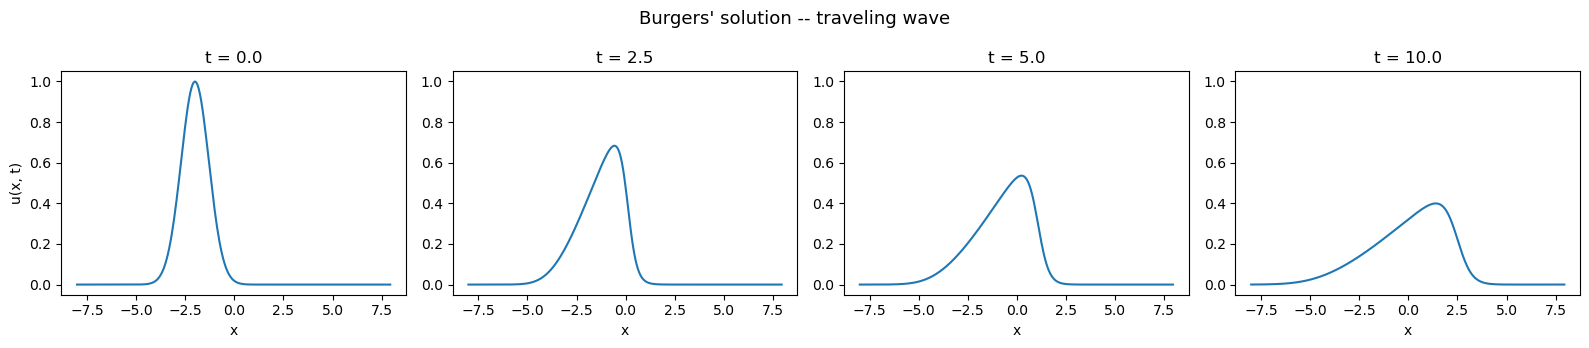

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, ti in zip(axes, [0, 25, 50, -1]):
    ax.plot(x, u[:, ti])
    ax.set_title(f't = {t[ti]:.1f}')
    ax.set_xlabel('x'); ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel('u(x, t)')
fig.suptitle("Burgers\' solution -- traveling wave", fontsize=13)
plt.tight_layout(); plt.show()

## 1. Standard library — validating regression and library construction

We build the standard coordinate-based library using **spectral (FFT) derivatives**, which are more accurate than the finite-difference stencils used by the original PDE-FIND code.  The library has $4 \times 4 = 16$ columns: products $u^p \cdot \partial_x^d u$ for $d = 0, 1, 2, 3$ and $p = 0, 1, 2, 3$.  We then run our `TrainSTRidge` and verify that it recovers the known Burgers equation.

In [4]:
# Build standard library over interior time steps
# Central FD in time:  u_t[:,j] = (u[:,j+1] - u[:,j-1]) / (2*dt)
Ut_list, R_list = [], []
for j in range(1, N_t - 1):
    Ut_list.append((u[:, j + 1] - u[:, j - 1]) / (2 * dt))
    Th_j, rhs_des = build_standard_library_1d(u[:, j], L, max_deriv=3, max_poly=3)
    R_list.append(Th_j)

Ut = np.concatenate(Ut_list)
R  = np.vstack(R_list).astype(float)

print(f'Library shape: {R.shape}  ({len(rhs_des)} columns)')
print(f'Target shape:  {Ut.shape}')
print('\nLibrary columns:')
for i, d in enumerate(rhs_des):
    print(f'  {i:2d}  {d}')

Library shape: (25344, 16)  (16 columns)
Target shape:  (25344,)

Library columns:
   0  1
   1  u
   2  u^2
   3  u^3
   4  u_x
   5  u*u_x
   6  u^2*u_x
   7  u^3*u_x
   8  u_xx
   9  u*u_xx
  10  u^2*u_xx
  11  u^3*u_xx
  12  u_xxx
  13  u*u_xxx
  14  u^2*u_xxx
  15  u^3*u_xxx


In [5]:
lam, d_tol = 1e-5, 0.1

print('=== Standard library — our TrainSTRidge ===')
w_std = TrainSTRidge(R, Ut, lam, d_tol)
print_pde(w_std, rhs_des)

# True Burgers: u_t = u_xx - u*u_x
# col 4 = u_x, col 5 = u*u_x (advection), col 8 = u_xx (diffusion)
nz_std = set(np.where(np.abs(w_std) > 1e-10)[0])
print(f'\nNon-zero columns: {sorted(nz_std)}')
print(f'u*u_x (col 5) recovered: {5 in nz_std}   coeff = {w_std[5]:.5f}  (true: -1.0)')
print(f'u_xx  (col 8) recovered: {8 in nz_std}   coeff = {w_std[8]:.5f}  (true: +0.1)')

=== Standard library — our TrainSTRidge ===
f_t = (-0.99787)u*u_x + (+0.09951)u_xx

Non-zero columns: [5, 8]
u*u_x (col 5) recovered: True   coeff = -0.99787  (true: -1.0)
u_xx  (col 8) recovered: True   coeff = 0.09951  (true: +0.1)


## 2. The 1D $O(1)$-equivariant library

Under the reflection $x \mapsto -x$, each derivative transforms as $\partial_x^n u \mapsto (-1)^n \partial_x^n u$.  An operator is $O(1)$-equivariant iff every odd-order derivative appears to an **even** power:

| Order | Operator | Equivariant? |
|---|---|---|
| 0 | $1$ | ✓ |
| 2 | $u_{xx},\;(u_x)^2$ | ✓ |
| 4 | $u_{xxxx},\;u_x u_{xxx},\;(u_{xx})^2,\;(u_x)^2 u_{xx}$ | ✓ |
| — | $u_x,\;u_{xxx}$ | ✗ |
| — | $u\,u_x$ ← required for Burgers | ✗ |

Each base operator is multiplied by $u^m$ ($m = 0, \ldots, n_{\max} - k$, where $k$ = number of $u$-factors in the operator).

In [6]:
def spectral_deriv_1d(u_field, L_dom, n):
    """n-th derivative of a 1D periodic field via FFT."""
    N = len(u_field)
    k = np.fft.fftfreq(N) * N * (2 * np.pi / L_dom)
    return np.real(np.fft.ifft((1j * k) ** n * np.fft.fft(u_field)))


def build_equivariant_library_1d(u_field, L_dom, max_order=4, max_poly=3):
    """O(1)-equivariant polynomial operator library for a 1D periodic field."""
    ux    = spectral_deriv_1d(u_field, L_dom, 1)
    uxx   = spectral_deriv_1d(u_field, L_dom, 2)
    uxxx  = spectral_deriv_1d(u_field, L_dom, 3)
    uxxxx = spectral_deriv_1d(u_field, L_dom, 4)

    # (array, description, k_base)
    base = [
        (np.ones_like(u_field), '1',           0),
        (uxx,                   'u_xx',         1),
        (ux ** 2,               '(u_x)^2',      2),
    ]
    if max_order >= 4:
        base += [
            (uxxxx,         'u_xxxx',           1),
            (ux * uxxx,     'u_x*u_xxx',        2),
            (uxx ** 2,      '(u_xx)^2',         2),
            (ux**2 * uxx,   '(u_x)^2*u_xx',    3),
        ]

    cols, descs = [], []
    for op, desc, k_b in base:
        max_m = max_poly - k_b
        if max_m < 0:
            continue
        for m in range(max_m + 1):
            if m == 0:
                cols.append(op.copy())
                descs.append(desc)
            else:
                cols.append(op * u_field ** m)
                prefix = f'u^{m}*' if m > 1 else 'u*'
                label  = prefix + desc if desc != '1' else (f'u^{m}' if m > 1 else 'u')
                descs.append(label)

    return np.column_stack(cols), descs


_, descs_eq = build_equivariant_library_1d(u[:, 50], L)
print(f'O(1)-equivariant library: {len(descs_eq)} columns')
for i, d in enumerate(descs_eq):
    print(f'  {i:2d}  {d}')

O(1)-equivariant library: 17 columns
   0  1
   1  u
   2  u^2
   3  u^3
   4  u_xx
   5  u*u_xx
   6  u^2*u_xx
   7  (u_x)^2
   8  u*(u_x)^2
   9  u_xxxx
  10  u*u_xxxx
  11  u^2*u_xxxx
  12  u_x*u_xxx
  13  u*u_x*u_xxx
  14  (u_xx)^2
  15  u*(u_xx)^2
  16  (u_x)^2*u_xx


In [7]:
# Build equivariant library over all interior time steps
# (central FD in time, same as PDE-FIND FD mode)
Ut_eq_list, Theta_eq_list = [], []
for j in range(1, N_t - 1):
    Ut_eq_list.append((u[:, j + 1] - u[:, j - 1]) / (2 * dt))
    Th_j, descs_eq = build_equivariant_library_1d(u[:, j], L, max_order=4, max_poly=3)
    Theta_eq_list.append(Th_j)

Ut_eq    = np.concatenate(Ut_eq_list)
Theta_eq = np.vstack(Theta_eq_list).astype(float)

print(f'Equivariant Theta shape : {Theta_eq.shape}')
print(f'Condition number        : {np.linalg.cond(Theta_eq):.2e}')

Equivariant Theta shape : (25344, 17)
Condition number        : 2.26e+03


In [8]:
lam_eq, d_tol_eq = 1e-5, 0.1

print('=== O(1)-equivariant PDE-find (1D) ===')
w_eq = TrainSTRidge(Theta_eq, Ut_eq, lam_eq, d_tol_eq)
print_pde(w_eq, descs_eq)

print('\n=== Standard library (reference) ===')
print_pde(w_std, rhs_des)

res_eq = np.linalg.norm(Ut_eq - Theta_eq @ w_eq) / np.linalg.norm(Ut_eq)
print(f'\nEquivariant library relative residual: {res_eq*100:.1f}%')
print('(Residual is high because u*u_x is absent from the equivariant library)')

=== O(1)-equivariant PDE-find (1D) ===
f_t = (-0.08571)u + (-0.56089)u^3 + (+0.07425)u_xx + (-1.27430)u*u_xx + (+1.41780)u^2*u_xx + (+1.73092)(u_x)^2 + (-3.73790)u*(u_x)^2 + (-0.04444)u*u_xxxx + (+0.06120)u^2*u_xxxx + (+0.15739)u_x*u_xxx + (-0.45842)u*u_x*u_xxx + (-0.10253)(u_xx)^2 + (+0.32343)u*(u_xx)^2

=== Standard library (reference) ===
f_t = (-0.99787)u*u_x + (+0.09951)u_xx

Equivariant library relative residual: 37.6%
(Residual is high because u*u_x is absent from the equivariant library)
